In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)



In [2]:
df = pd.read_csv("/kaggle/input/datasets/saurabh00007/iriscsv/Iris.csv")

In [3]:
df

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...,...
145,146,6.7,3.0,5.2,2.3,Iris-virginica
146,147,6.3,2.5,5.0,1.9,Iris-virginica
147,148,6.5,3.0,5.2,2.0,Iris-virginica
148,149,6.2,3.4,5.4,2.3,Iris-virginica


In [4]:
df = df.iloc[:,1:]

In [5]:
from sklearn.preprocessing import LabelEncoder

In [6]:
encoder = LabelEncoder()

In [7]:
df['Species'] = encoder.fit_transform(df['Species'])

In [8]:
df.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [9]:
df = df[df['Species'] != 0][['SepalWidthCm','PetalLengthCm','Species']]

In [10]:
df.head()

,SepalWidthCm,PetalLengthCm,Species
50,3.2,4.7,1
51,3.2,4.5,1
52,3.1,4.9,1
53,2.3,4.0,1
54,2.8,4.6,1


In [11]:
df.shape

(100, 3)

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

<Axes: xlabel='SepalWidthCm', ylabel='PetalLengthCm'>

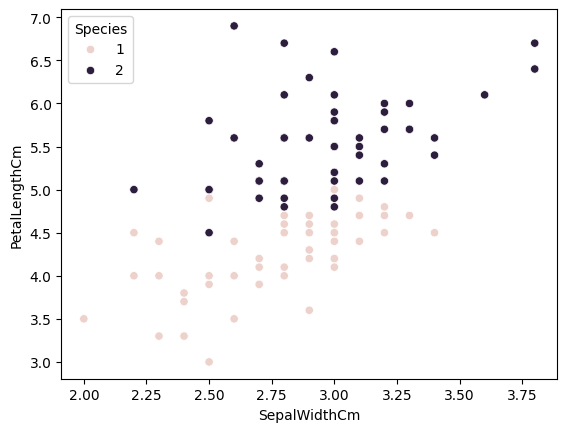

In [13]:
sns.scatterplot(df,x='SepalWidthCm',y='PetalLengthCm',hue='Species')

In [14]:
# Taking only 10 rows for training
df = df.sample(100)
df_train = df.iloc[:60,:].sample(10)
df_val = df.iloc[60:80,:].sample(5)
df_test = df.iloc[80:,:].sample(8)

In [15]:
df_test

,SepalWidthCm,PetalLengthCm,Species
74,2.9,4.3,1
105,3.0,6.6,2
84,3.0,4.5,1
53,2.3,4.0,1
59,2.7,3.9,1
132,2.8,5.6,2
68,2.2,4.5,1
93,2.3,3.3,1


In [16]:
X_test = df_val.iloc[:,0:2].values
y_test = df_val.iloc[:,-1].values

In [17]:
X_test

array([[3.3, 4.7],
       [2.7, 5.3],
       [2.5, 4.5],
       [3.1, 4.7],
       [2.8, 6.7]])

In [18]:
y_test

array([1, 2, 2, 1, 2])

# Bagging

In [19]:
# Data for Tree 1
df_bag = df_train.sample(8,replace=True)

In [20]:
X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]


In [21]:
df_bag

,SepalWidthCm,PetalLengthCm,Species
80,2.4,3.8,1
119,2.2,5.0,2
115,3.2,5.3,2
134,2.6,5.6,2
117,3.8,6.7,2
134,2.6,5.6,2
115,3.2,5.3,2
117,3.8,6.7,2


In [22]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from mlxtend.plotting import plot_decision_regions
from sklearn.metrics import accuracy_score

In [23]:
dt_bag1 = DecisionTreeClassifier()

In [24]:
def evaluate(clf,X,y):
    clf.fit(X,y)
    plot_tree(clf)
    plt.show()
    plot_decision_regions(X.values, y.values, clf=clf, legend=2)
    y_pred = clf.predict(X_test)
    print(accuracy_score(y_test,y_pred))

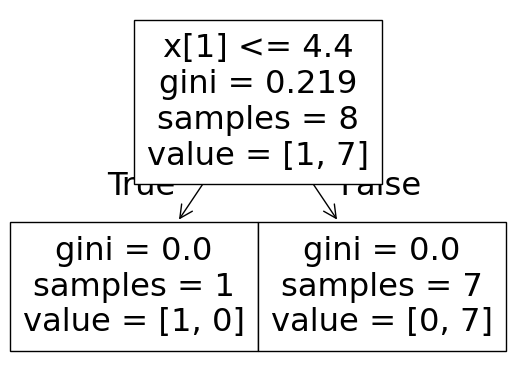

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


0.6


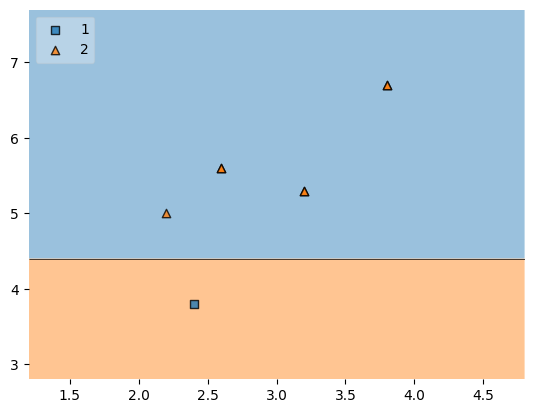

In [25]:
evaluate(dt_bag1,X,y)

In [26]:
# Data for Tree 2
df_bag = df_train.sample(8,replace=True)

# Fetch X and y
X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]

# print df_bag
df_bag

,SepalWidthCm,PetalLengthCm,Species
78,2.9,4.5,1
115,3.2,5.3,2
134,2.6,5.6,2
120,3.2,5.7,2
115,3.2,5.3,2
120,3.2,5.7,2
120,3.2,5.7,2
115,3.2,5.3,2


In [27]:
dt_bag2 = DecisionTreeClassifier()

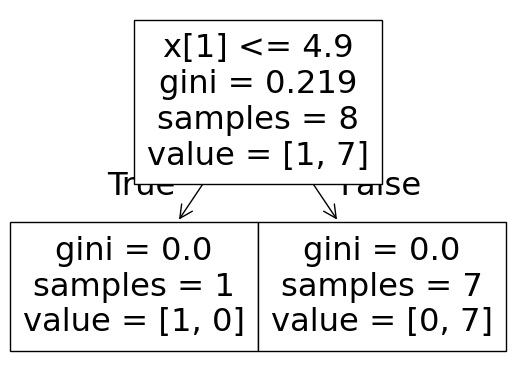

0.8


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


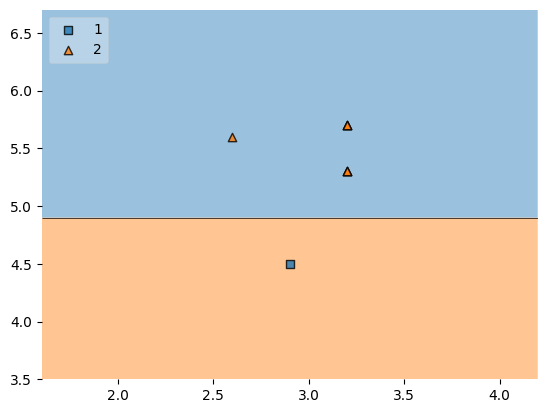

In [28]:
evaluate(dt_bag2,X,y)

In [29]:
# Data for Tree 3
df_bag = df_train.sample(8,replace=True)

# Fetch X and y
X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]

# print df_bag
df_bag

,SepalWidthCm,PetalLengthCm,Species
115,3.2,5.3,2
134,2.6,5.6,2
115,3.2,5.3,2
82,2.7,3.9,1
115,3.2,5.3,2
82,2.7,3.9,1
120,3.2,5.7,2
90,2.6,4.4,1


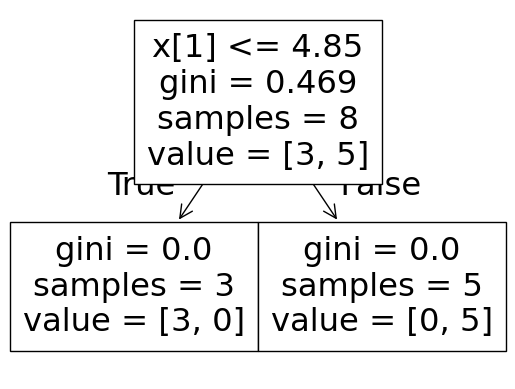

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


0.8


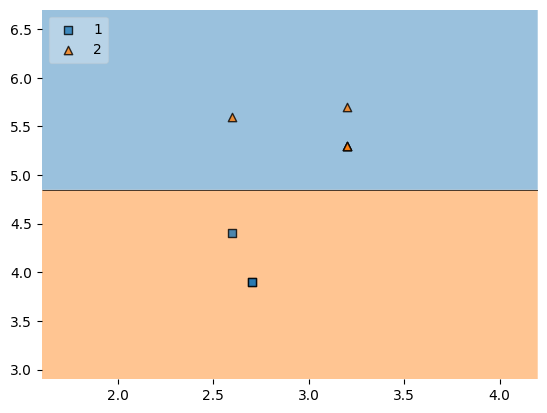

In [30]:
dt_bag3 = DecisionTreeClassifier()
evaluate(dt_bag3,X,y)

# Prediction

In [31]:
df_test

,SepalWidthCm,PetalLengthCm,Species
74,2.9,4.3,1
105,3.0,6.6,2
84,3.0,4.5,1
53,2.3,4.0,1
59,2.7,3.9,1
132,2.8,5.6,2
68,2.2,4.5,1
93,2.3,3.3,1


In [32]:
print("Predictor 1",dt_bag1.predict(np.array([2.0,3.5]).reshape(1,2)))
print("Predictor 2",dt_bag2.predict(np.array([2.0,3.5]).reshape(1,2)))
print("Predictor 3",dt_bag3.predict(np.array([2.0,3.5]).reshape(1,2)))

Predictor 1 [1]
Predictor 2 [1]
Predictor 3 [1]


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


# Pasting

In [33]:
# Row sampling without replacement
df_train

,SepalWidthCm,PetalLengthCm,Species
115,3.2,5.3,2
112,3.0,5.5,2
82,2.7,3.9,1
78,2.9,4.5,1
134,2.6,5.6,2
117,3.8,6.7,2
120,3.2,5.7,2
80,2.4,3.8,1
90,2.6,4.4,1
119,2.2,5.0,2


In [34]:
df_train.sample(8)

,SepalWidthCm,PetalLengthCm,Species
115,3.2,5.3,2
78,2.9,4.5,1
82,2.7,3.9,1
80,2.4,3.8,1
112,3.0,5.5,2
134,2.6,5.6,2
120,3.2,5.7,2
117,3.8,6.7,2


In [35]:
# Data for m1
df_bag = df_train.sample(8)
# Fetch X and y
X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]

# print df_bag
df_bag

,SepalWidthCm,PetalLengthCm,Species
78,2.9,4.5,1
80,2.4,3.8,1
117,3.8,6.7,2
82,2.7,3.9,1
134,2.6,5.6,2
112,3.0,5.5,2
115,3.2,5.3,2
119,2.2,5.0,2


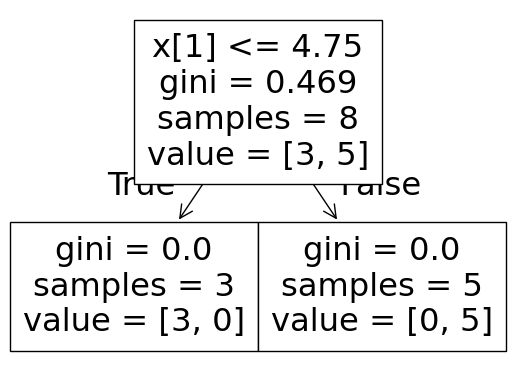

0.8


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


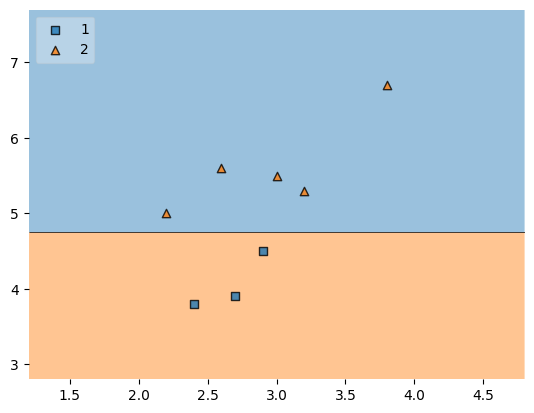

In [36]:
dt_bag1 = DecisionTreeClassifier()
evaluate(dt_bag1,X,y)

In [37]:
# Data for m2
df_bag = df_train.sample(8)
# Fetch X and y
X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]

# print df_bag
df_bag

,SepalWidthCm,PetalLengthCm,Species
117,3.8,6.7,2
80,2.4,3.8,1
90,2.6,4.4,1
82,2.7,3.9,1
119,2.2,5.0,2
112,3.0,5.5,2
120,3.2,5.7,2
115,3.2,5.3,2


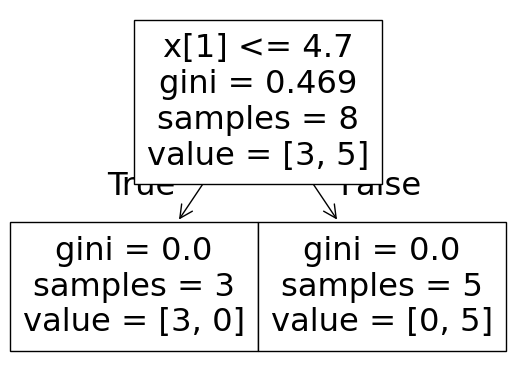

0.8


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


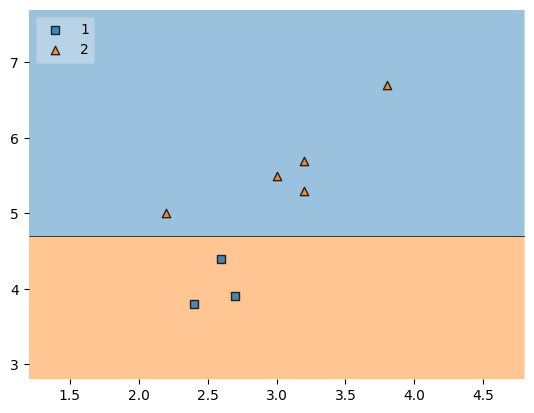

In [38]:
dt_bag2 = DecisionTreeClassifier()
evaluate(dt_bag2,X,y)

In [39]:
# Data for m3
df_bag = df_train.sample(8)
# Fetch X and y
X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]

# print df_bag
df_bag

,SepalWidthCm,PetalLengthCm,Species
117,3.8,6.7,2
78,2.9,4.5,1
134,2.6,5.6,2
90,2.6,4.4,1
115,3.2,5.3,2
112,3.0,5.5,2
80,2.4,3.8,1
82,2.7,3.9,1


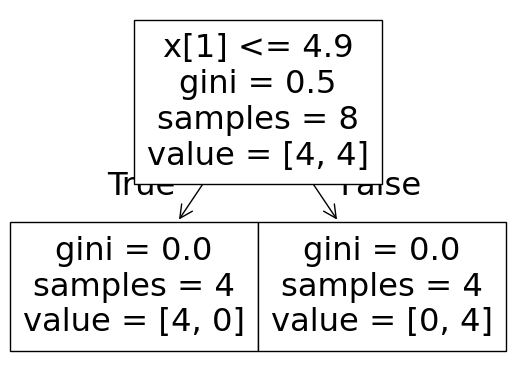

0.8


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


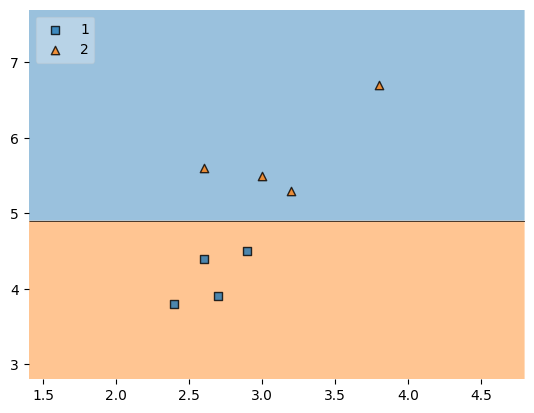

In [40]:
dt_bag3 = DecisionTreeClassifier()
evaluate(dt_bag3,X,y)

In [41]:
df_test

,SepalWidthCm,PetalLengthCm,Species
74,2.9,4.3,1
105,3.0,6.6,2
84,3.0,4.5,1
53,2.3,4.0,1
59,2.7,3.9,1
132,2.8,5.6,2
68,2.2,4.5,1
93,2.3,3.3,1


In [42]:
print("Predictor 1",dt_bag1.predict(np.array([2.9,4.5]).reshape(1,2)))
print("Predictor 2",dt_bag2.predict(np.array([2.9,4.5]).reshape(1,2)))
print("Predictor 3",dt_bag3.predict(np.array([2.9,4.5]).reshape(1,2)))

Predictor 1 [1]
Predictor 2 [1]
Predictor 3 [1]


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


# Random Subspaces
columns wala

In [43]:
df1 = pd.read_csv('/kaggle/input/datasets/saurabh00007/iriscsv/Iris.csv')
df1 = df1.sample(10)

In [44]:
df1

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
140,141,6.7,3.1,5.6,2.4,Iris-virginica
68,69,6.2,2.2,4.5,1.5,Iris-versicolor
15,16,5.7,4.4,1.5,0.4,Iris-setosa
8,9,4.4,2.9,1.4,0.2,Iris-setosa
121,122,5.6,2.8,4.9,2.0,Iris-virginica
145,146,6.7,3.0,5.2,2.3,Iris-virginica
5,6,5.4,3.9,1.7,0.4,Iris-setosa
115,116,6.4,3.2,5.3,2.3,Iris-virginica
13,14,4.3,3.0,1.1,0.1,Iris-setosa
149,150,5.9,3.0,5.1,1.8,Iris-virginica


In [45]:
df1.sample(2,replace=True,axis=1)

,SepalLengthCm,Id
140,6.7,141
68,6.2,69
15,5.7,16
8,4.4,9
121,5.6,122
145,6.7,146
5,5.4,6
115,6.4,116
13,4.3,14
149,5.9,150
